# Machine Failure Prediction — AI4I 2020

**Goal:** Predict the `Machine failure` target from machine operating measurements.  
**Dataset:** UCI AI4I 2020 Predictive Maintenance Dataset (10,000 rows).  
**Important:** Failure-type columns (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) and ID columns are excluded to prevent target leakage. This notebook uses a stratified 80/20 split and reports confusion matrix, precision, and recall.

In [ ]:
# Install once if needed:
# %pip install -r requirements.txt

from pathlib import Path
import urllib.request

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
DATASET_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00601/ai4i2020.csv"
CSV_PATH = Path("ai4i2020.csv")

if not CSV_PATH.exists():
    print(f"Dataset not found locally. Downloading from {DATASET_URL}...")
    urllib.request.urlretrieve(DATASET_URL, CSV_PATH)
    print(f"Downloaded to {CSV_PATH.resolve()}")


## 1. Load and inspect

In [12]:
# Load the AI4I 2020 machine-failure dataset.
# If the CSV is missing locally, the setup cell above downloads it automatically.
df = pd.read_csv(CSV_PATH)

display(df.head())
print("Shape:", df.shape)
print("\nMissing values per column:")
display(df.isna().sum())
print("\nTarget counts:")
display(df["Machine failure"].value_counts(dropna=False))
print("Failure prevalence:", df["Machine failure"].mean())


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


Shape: (10000, 14)
\nMissing values per column:


UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

\nTarget counts:


Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure prevalence: 0.0339


## 2. Explore two relationships

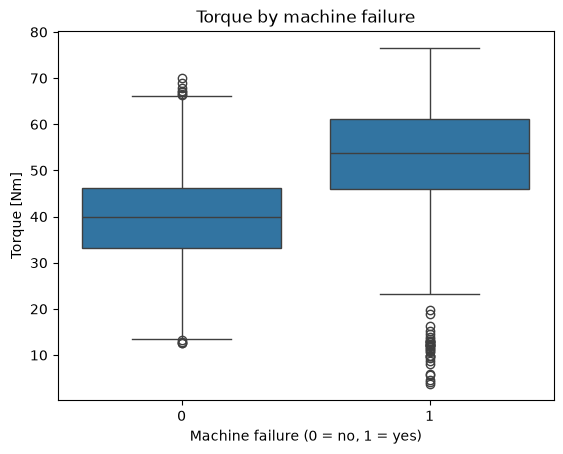

Interpretation: Compare the torque distributions; overlap means torque alone cannot reliably separate failures.


In [13]:
# Plot 1: torque distribution by failure status
sns.boxplot(data=df, x="Machine failure", y="Torque [Nm]")
plt.title("Torque by machine failure")
plt.xlabel("Machine failure (0 = no, 1 = yes)")
plt.show()
print("Interpretation: Compare the torque distributions; overlap means torque alone cannot reliably separate failures.")


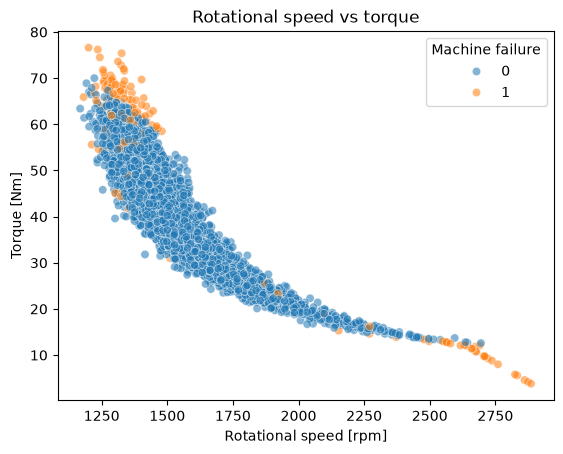

Interpretation: Failure points may cluster in operating regions, but visual overlap indicates other features matter.


In [14]:
# Plot 2: rotational speed against torque, colored by failure
sns.scatterplot(data=df, x="Rotational speed [rpm]", y="Torque [Nm]",
                hue="Machine failure", alpha=0.55)
plt.title("Rotational speed vs torque")
plt.show()
print("Interpretation: Failure points may cluster in operating regions, but visual overlap indicates other features matter.")


## 3. Prepare data

Drop `UDI`, `Product ID`, and the five failure-type columns. Keeping the failure-type columns would be cheating because they are derived from/strongly encode the failure outcome and would reveal the target to the model (target leakage).

In [15]:
target = "Machine failure"
leakage_cols = ["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"]
X = df.drop(columns=[target] + leakage_cols, errors="raise")
X = pd.get_dummies(X, columns=["Type"], drop_first=True)
y = df[target].astype(int)

print("Features:", X.columns.tolist())
print("Target counts:", y.value_counts().to_dict())


Features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_L', 'Type_M']
Target counts: {0: 9661, 1: 339}


## 4. Split and train a model
A decision tree is used as a simple, explainable baseline. Stratification preserves the rare-failure proportion in each split.

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

model = DecisionTreeClassifier(
    max_depth=6,
    class_weight="balanced",
    random_state=RANDOM_STATE
)
model.fit(X_train, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_feat

## 5. Evaluate on the held-out test set

Confusion matrix (rows=true, columns=predicted; labels=[0,1]):
[[1815  117]
 [  10   58]]
Failure precision: 0.3314285714285714
Failure recall: 0.8529411764705882
              precision    recall  f1-score   support

           0       0.99      0.94      0.97      1932
           1       0.33      0.85      0.48        68

    accuracy                           0.94      2000
   macro avg       0.66      0.90      0.72      2000
weighted avg       0.97      0.94      0.95      2000



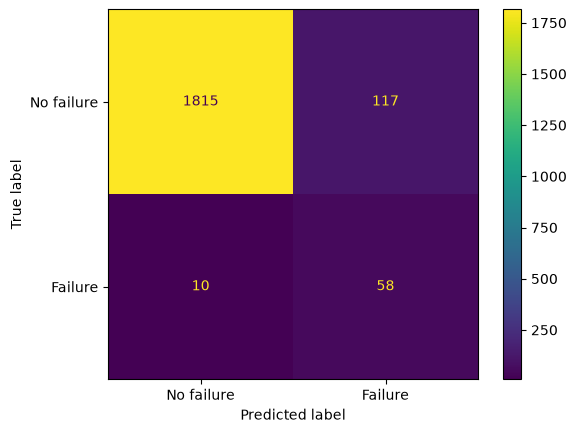

In [17]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, precision_score,
    recall_score, classification_report
)

y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("Confusion matrix (rows=true, columns=predicted; labels=[0,1]):")
print(cm)
print("Failure precision:", precision_score(y_test, y_pred, zero_division=0))
print("Failure recall:", recall_score(y_test, y_pred, zero_division=0))
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No failure", "Failure"]).plot()
plt.show()


## 6. Results discussion (complete after running)

Use the actual printed values in the final report; do not invent metrics.

- The confusion matrix shows true negatives, false positives, false negatives, and true positives.
- Failure precision is the share of predicted failures that were actual failures. Low precision can cause unnecessary inspections.
- Failure recall is the share of actual failures detected. Low recall means missed failures, which can be costly.
- Failures are rare, so a model that predicts “no failure” for every row can achieve high accuracy while detecting no failures.
- This baseline is not deployment-ready. Evaluate cost-sensitive thresholds, calibration, temporal/generalization behavior, and operational consequences before use.
- The dataset is synthetic and may not represent a specific factory's equipment or failure distribution.

## 7. Test sample machine readings

These sample rows omit `Type`. After aligning to the training columns, their all-zero `Type_L` and `Type_M` values represent the baseline category `H`.

In [18]:
test_cases = pd.DataFrame(
    [
        [300, 1500, 40, 20, 100],
        [310, 1450, 45, 25, 110],
        [290, 1600, 35, 18, 95],
        [320, 1300, 55, 30, 120],
    ],
    columns=[
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]",
    ],
)

# Add dummy columns if a categorical feature such as Type is provided.
test_cases = pd.get_dummies(test_cases)
test_cases = test_cases.reindex(columns=X_train.columns, fill_value=0)

predictions = model.predict(test_cases)
for i, prediction in enumerate(predictions, start=1):
    result = "FAILURE" if prediction == 1 else "NO FAILURE"
    print(f"Test Case {i}: {result}")

Test Case 1: NO FAILURE
Test Case 2: NO FAILURE
Test Case 3: NO FAILURE
Test Case 4: NO FAILURE


## 8. Test actual failure records

This checks the first 10 known failure records using the same `Type` one-hot encoding as training. Because the model was trained using a split of this dataset, these examples are not an independent evaluation set.

In [19]:
failure_data = df[df["Machine failure"] == 1].copy()
failure_data = failure_data.drop(
    columns=[
        "UDI",
        "Product ID",
        "TWF",
        "HDF",
        "PWF",
        "OSF",
        "RNF",
        "Machine failure",
    ],
    errors="ignore",
)
failure_data = pd.get_dummies(failure_data, columns=["Type"], drop_first=True)
failure_data = failure_data.reindex(columns=X_train.columns, fill_value=0)

failure_predictions = model.predict(failure_data.head(10))
for i, prediction in enumerate(failure_predictions, start=1):
    result = "FAILURE" if prediction == 1 else "NO FAILURE"
    print(f"Actual Failure Test {i}: {result}")

Actual Failure Test 1: FAILURE
Actual Failure Test 2: FAILURE
Actual Failure Test 3: FAILURE
Actual Failure Test 4: FAILURE
Actual Failure Test 5: FAILURE
Actual Failure Test 6: FAILURE
Actual Failure Test 7: FAILURE
Actual Failure Test 8: FAILURE
Actual Failure Test 9: FAILURE
Actual Failure Test 10: FAILURE
